In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [3]:
import numpy as np
import pandas as pd

def reduce_mem_usage(df):
    """
    遍历DataFrame的所有列，修改数据类型以减少内存使用
    
    :param df: 输入的DataFrame
    :return: 优化内存后的DataFrame
    """
    # 记录原始内存使用情况
    start_mem = df.memory_usage().sum() / 1024**2
    print(f'原始内存使用: {start_mem:.2f} MB')
    
    # 遍历每一列
    for col in df.columns:
        col_type = df[col].dtype
        
        # 处理数值类型（非对象类型）
        if col_type != object:
            c_min = df[col].min()
            c_max = df[col].max()
            
            # 处理整数类型
            if str(col_type)[:3] == 'int':
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
                elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                    df[col] = df[col].astype(np.int64)
            
            # 处理浮点数类型
            else:
                if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
                    df[col] = df[col].astype(np.float16)
                elif c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[col] = df[col].astype(np.float32)
                else:
                    df[col] = df[col].astype(np.float64)
        
        # 处理对象类型（字符串等）
        else:
            df[col] = df[col].astype('category')
    
    # 计算优化后的内存使用情况
    end_mem = df.memory_usage().sum() / 1024**2
    print(f'优化后内存使用: {end_mem:.2f} MB')
    print(f'内存减少: {(start_mem - end_mem)/start_mem:.1%}')
    
    return df

In [4]:
sample_feature = reduce_mem_usage(pd.read_csv('data_for_tree.csv'))

原始内存使用: 80.48 MB
优化后内存使用: 22.59 MB
内存减少: 71.9%


In [5]:
continuous_feature_names = [x for x in sample_feature.columns if x not in ['price','brand','model','brand']]

In [6]:
sample_feature = sample_feature.dropna().replace('-', 0).reset_index(drop=True)
sample_feature['notRepairedDamage'] = sample_feature['notRepairedDamage'].astype(np.float32)
train = sample_feature[continuous_feature_names + ['price']]
train_X = train[continuous_feature_names]
train_y = train['price']

In [7]:
from sklearn.linear_model import LinearRegression

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 创建包含标准化和线性回归的管道
model = make_pipeline(
    StandardScaler(),  # 标准化特征（减去均值，除以标准差）
    LinearRegression()
)

In [10]:
model = model.fit(train_X, train_y)

In [14]:
# 获取 Pipeline 中的最终估计器
final_estimator = model[-1]  # 或 model.named_steps['regressor']，取决于你如何命名估计器

# 打印截距
print('intercept:', final_estimator.intercept_)

# 获取连续特征的系数并排序
coef_dict = dict(zip(continuous_feature_names, final_estimator.coef_))
sorted_coefs = sorted(coef_dict.items(), key=lambda x: x[1], reverse=True)
print(sorted_coefs)

intercept: 6105.896502425314
[('v_6', 149268.7705774294), ('v_12', 77550.66058978032), ('v_3', 71846.4856873123), ('v_11', 33841.12311372165), ('v_13', 24159.729323988653), ('v_8', 21029.26802014772), ('v_10', 15532.99731493115), ('v_9', 3947.452915364898), ('v_5', 3392.532828714751), ('power', 3004.9795401891215), ('bodyType', 521.4861138648628), ('gearbox', 367.9272792412617), ('city', 151.67968203183796), ('fuelType', 52.697083827357964), ('name', 12.56530533481805), ('offerType', 8.325287126353942e-09), ('train', 2.9103830456733704e-11), ('brand_amount_x', 0.0), ('brand_price_average_x', 0.0), ('brand_price_max_x', 0.0), ('brand_price_median_x', 0.0), ('brand_price_min_x', 0.0), ('brand_price_std_x', 0.0), ('brand_price_sum_x', 0.0), ('brand_amount_y', 0.0), ('brand_price_max_y', 0.0), ('brand_price_median_y', 0.0), ('brand_price_min_y', 0.0), ('brand_price_sum_y', 0.0), ('brand_price_std_y', 0.0), ('brand_price_average_y', 0.0), ('brand_amount', 0.0), ('brand_price_max', 0.0), ('b

In [15]:
from matplotlib import pyplot as plt

In [16]:
subsample_index = np.random.randint(low=0, high=len(train_y), size=50)

The predicted price is obvious different from true price


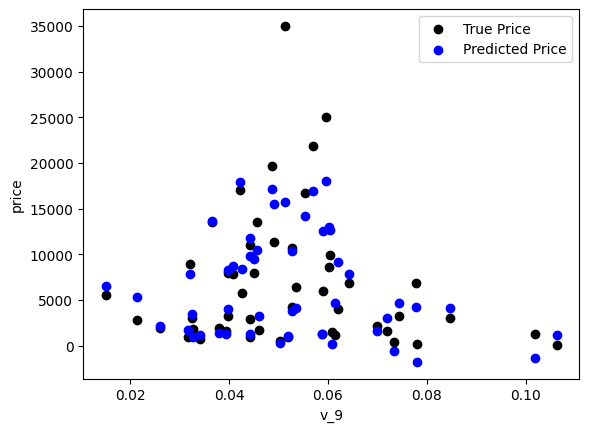

In [17]:
plt.scatter(train_X['v_9'][subsample_index], train_y[subsample_index], color='black')
plt.scatter(train_X['v_9'][subsample_index], model.predict(train_X.loc[subsample_index]), color='blue')
plt.xlabel('v_9')
plt.ylabel('price')
plt.legend(['True Price','Predicted Price'],loc='upper right')
print('The predicted price is obvious different from true price')
plt.show()

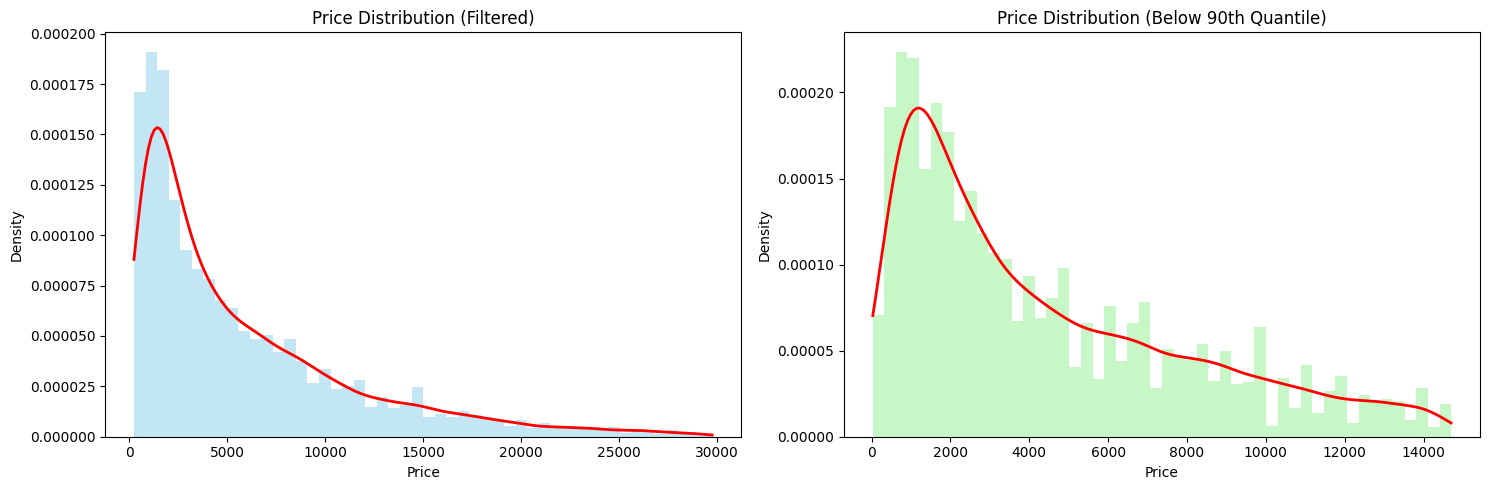

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# 强制转换为纯 NumPy 数组（关键步骤）
train_y_np = np.array(train_y).ravel()  # ravel() 比 flatten() 更彻底地解除与原数据的关联
train_y_np = train_y_np[~np.isnan(train_y_np)]
train_y_np = train_y_np[~np.isinf(train_y_np)]

# 过滤极端值（保留 1%-99% 分位数）
q1, q99 = np.percentile(train_y_np, [1, 99])
train_y_np_filtered = train_y_np[(train_y_np >= q1) & (train_y_np <= q99)]

# 计算 90% 分位数数据
q90 = np.percentile(train_y_np, 90)
train_y_np_below90 = train_y_np[train_y_np < q90]

# 创建画布
plt.figure(figsize=(15, 5))

# 子图 1：完整过滤后的数据 + 手动 KDE
plt.subplot(1, 2, 1)
# 绘制直方图
n, bins, patches = plt.hist(
    train_y_np_filtered, 
    bins=50, 
    density=True, 
    alpha=0.5, 
    color='skyblue'
)
# 手动计算 KDE
kde = stats.gaussian_kde(train_y_np_filtered)
x_range = np.linspace(bins.min(), bins.max(), 200)
plt.plot(x_range, kde(x_range), color='red', linewidth=2)
plt.title('Price Distribution (Filtered)')
plt.xlabel('Price')
plt.ylabel('Density')

# 子图 2：90% 分位数以下数据 + 手动 KDE
plt.subplot(1, 2, 2)
# 绘制直方图
n, bins, patches = plt.hist(
    train_y_np_below90, 
    bins=50, 
    density=True, 
    alpha=0.5, 
    color='lightgreen'
)
# 手动计算 KDE
kde = stats.gaussian_kde(train_y_np_below90)
x_range = np.linspace(bins.min(), bins.max(), 200)
plt.plot(x_range, kde(x_range), color='red', linewidth=2)
plt.title('Price Distribution (Below 90th Quantile)')
plt.xlabel('Price')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

In [25]:
train_y_ln = np.log(train_y + 1)

对数转换后的数据统计信息:
样本数: 19585
最小值: 3.43
最大值: 11.13
均值: 8.17
标准差: 1.12


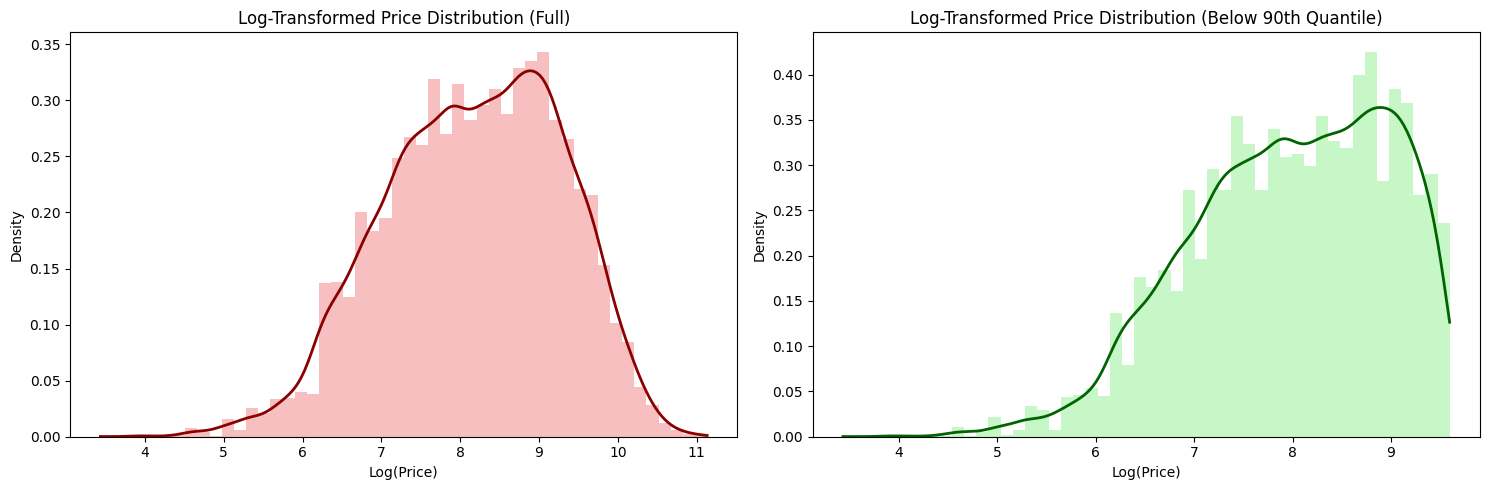

In [28]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# 强制转换为纯 NumPy 一维数组（关键步骤）
train_y_ln_np = np.array(train_y_ln).ravel()  # 彻底脱离 Pandas 数据结构
train_y_ln_np = train_y_ln_np[~np.isnan(train_y_ln_np)]  # 过滤无效值
train_y_ln_np = train_y_ln_np[~np.isinf(train_y_ln_np)]

print('对数转换后的数据统计信息:')
print(f"样本数: {len(train_y_ln_np)}")
print(f"最小值: {np.min(train_y_ln_np):.2f}")
print(f"最大值: {np.max(train_y_ln_np):.2f}")
print(f"均值: {np.mean(train_y_ln_np):.2f}")
print(f"标准差: {np.std(train_y_ln_np):.2f}")

# 创建画布
plt.figure(figsize=(15, 5))

# 子图 1：完整对数转换数据 + 手动 KDE
plt.subplot(1, 2, 1)
# 绘制直方图
n, bins, patches = plt.hist(
    train_y_ln_np, 
    bins=50, 
    density=True, 
    alpha=0.5, 
    color='lightcoral'
)
# 手动计算 KDE 曲线
kde = stats.gaussian_kde(train_y_ln_np)
x_range = np.linspace(bins.min(), bins.max(), 200)
plt.plot(x_range, kde(x_range), color='darkred', linewidth=2)
plt.title('Log-Transformed Price Distribution (Full)')
plt.xlabel('Log(Price)')
plt.ylabel('Density')

# 子图 2：90% 分位数以下的对数转换数据 + 手动 KDE
plt.subplot(1, 2, 2)
# 计算 90% 分位数并过滤数据
q90 = np.percentile(train_y_ln_np, 90)
train_y_ln_below90 = train_y_ln_np[train_y_ln_np < q90]
# 绘制直方图
n, bins, patches = plt.hist(
    train_y_ln_below90, 
    bins=50, 
    density=True, 
    alpha=0.5, 
    color='lightgreen'
)
# 手动计算 KDE 曲线
kde = stats.gaussian_kde(train_y_ln_below90)
x_range = np.linspace(bins.min(), bins.max(), 200)
plt.plot(x_range, kde(x_range), color='darkgreen', linewidth=2)
plt.title('Log-Transformed Price Distribution (Below 90th Quantile)')
plt.xlabel('Log(Price)')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

In [33]:
# 训练模型（保持不变）
model = model.fit(train_X, train_y_ln)

# 从 Pipeline 中提取最终的回归模型
final_estimator = model.named_steps['regressor']  # 替换 'regressor' 为你 Pipeline 中最后一步的名称

# 访问截距和系数
print('intercept:', final_estimator.intercept_)

# 按系数绝对值排序（从大到小）
coef_dict = dict(zip(continuous_feature_names, final_estimator.coef_))
sorted_coefs = sorted(coef_dict.items(), key=lambda x: abs(x[1]), reverse=True)
print("按系数绝对值排序:")
for feature, coef in sorted_coefs:
    print(f"{feature}: {coef:.4f}")

intercept: 8.17389374855437
按系数绝对值排序:
v_12: 13.0782
v_6: -12.1095
v_3: 7.3568
v_1: 6.5144
v_11: 4.6205
v_10: -2.8499
v_8: -2.1445
v_2: -1.9913
v_13: 1.3452
v_7: -1.1370
v_4: -1.0991
v_5: -0.5436
v_0: -0.3451
power_bin: 0.1771
v_9: -0.1327
power: -0.1205
notRepairedDamage: -0.0671
kilometer: -0.0425
bodyType: 0.0213
used_time: -0.0184
v_14: -0.0116
fuelType: 0.0056
SaleID: 0.0032
gearbox: 0.0014
city: -0.0004
name: -0.0002
seller: -0.0000
offerType: -0.0000
train: -0.0000
brand_amount_x: 0.0000
brand_price_average_x: 0.0000
brand_price_max_x: 0.0000
brand_price_median_x: 0.0000
brand_price_min_x: 0.0000
brand_price_std_x: 0.0000
brand_price_sum_x: 0.0000
brand_amount_y: 0.0000
brand_price_max_y: 0.0000
brand_price_median_y: 0.0000
brand_price_min_y: 0.0000
brand_price_sum_y: 0.0000
brand_price_std_y: 0.0000
brand_price_average_y: 0.0000
brand_amount: 0.0000
brand_price_max: 0.0000
brand_price_median: 0.0000
brand_price_min: 0.0000
brand_price_sum: 0.0000
brand_price_std: 0.0000
brand_pr

The predicted price seems normal after np.log transforming


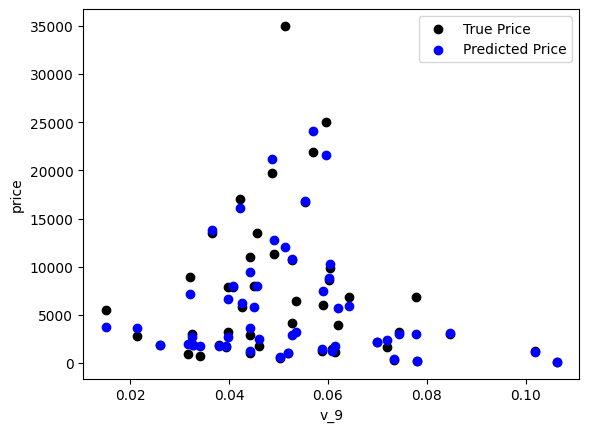

In [34]:
plt.scatter(train_X['v_9'][subsample_index], train_y[subsample_index], color='black')
plt.scatter(train_X['v_9'][subsample_index], np.exp(model.predict(train_X.loc[subsample_index])), color='blue')
plt.xlabel('v_9')
plt.ylabel('price')
plt.legend(['True Price','Predicted Price'],loc='upper right')
print('The predicted price seems normal after np.log transforming')
plt.show()

In [35]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error,  make_scorer

In [37]:
def log_transfer(func):
    def wrapper(y, yhat):
        result = func(np.log(y), np.nan_to_num(np.log(yhat)))
        return result
    return wrapper

In [38]:
 scores = cross_val_score(model, X=train_X, y=train_y, verbose=1, cv = 5, scoring=make_scorer(log_transfer(mean_absolute_error)))

[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.2s finished


In [39]:
print('AVG:', np.mean(scores))

AVG: 1.2488607089844161


In [40]:
 scores = cross_val_score(model, X=train_X, y=train_y_ln, verbose=1, cv = 5, scoring=make_scorer(mean_absolute_error))

[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.2s finished


In [41]:
print('AVG:', np.mean(scores))

AVG: 0.1874195096806404


In [42]:
scores = pd.DataFrame(scores.reshape(1,-1))
scores.columns = ['cv' + str(x) for x in range(1, 6)]
scores.index = ['MAE']
scores

,cv1,cv2,cv3,cv4,cv5
MAE,0.181918,0.186872,0.189409,0.184908,0.19399


In [43]:
import datetime

In [44]:
sample_feature = sample_feature.reset_index(drop=True)

In [45]:
split_point = len(sample_feature) // 5 * 4

In [46]:
train = sample_feature.loc[:split_point].dropna()
val = sample_feature.loc[split_point:].dropna()
train_X = train[continuous_feature_names]
train_y_ln = np.log(train['price'] + 1)
val_X = val[continuous_feature_names]
val_y_ln = np.log(val['price'] + 1)

In [47]:
 model = model.fit(train_X, train_y_ln)

In [48]:
 mean_absolute_error(val_y_ln, model.predict(val_X))

0.19398707093204356

In [49]:
from sklearn.model_selection import learning_curve, validation_curve

In [51]:
? learning_curve

In [53]:
def plot_learning_curve(estimator, title, X, y, ylim=None, cv=None, n_jobs=1, train_size=np.linspace(.1, 1.0, 5)):
    plt.figure()
    plt.title(title)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel('Training example')
    plt.ylabel('score')
    
    # 修复这里：添加了缺失的右括号
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_size,
        scoring=make_scorer(mean_absolute_error)  # 这里添加了缺失的右括号
    )
    
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)
    
    plt.grid()  # 添加网格
    plt.fill_between(
        train_sizes,
        train_scores_mean - train_scores_std,
        train_scores_mean + train_scores_std,
        alpha=0.1,
        color="r"
    )
    plt.fill_between(
        train_sizes,
        test_scores_mean - test_scores_std,
        test_scores_mean + test_scores_std,
        alpha=0.1,
        color="g"
    )
    plt.plot(
        train_sizes,
        train_scores_mean,
        'o-',
        color='r',
        label="Training score"
    )
    plt.plot(
        train_sizes,
        test_scores_mean,
        'o-',
        color="g",
        label="Cross-validation score"
    )
    
    plt.legend(loc="best")
    return plt

<module 'matplotlib.pyplot' from 'C:\\Users\\Lenovo\\.conda\\envs\\datasci\\lib\\site-packages\\matplotlib\\pyplot.py'>

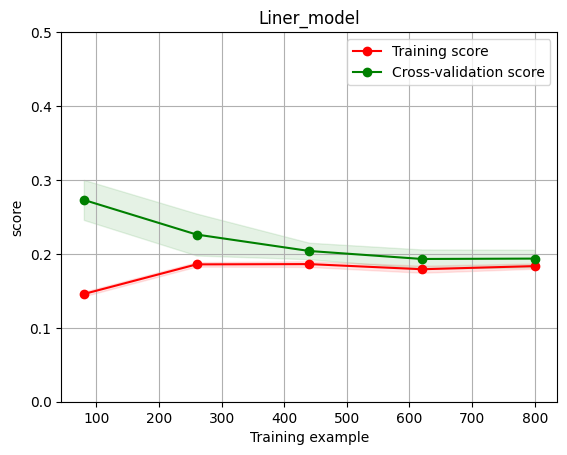

In [54]:
plot_learning_curve(LinearRegression(), 'Liner_model', train_X[:1000], train_y_ln[:1000], ylim=(0.0, 0.5), cv=5, n_jobs=1)  

In [57]:
train = sample_feature[continuous_feature_names + ['price']].dropna()
train_X = train[continuous_feature_names]
train_y = train['price']
train_y_ln = np.log(train_y + 1)

In [58]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

In [59]:
models = [LinearRegression(),
          Ridge(),
          Lasso()]

In [60]:
result = dict()
for model in models:
    model_name = str(model).split('(')[0]
    scores = cross_val_score(model, X=train_X, y=train_y_ln, verbose=0, cv = 5, scoring=make_scorer(mean_absolute_error))
    result[model_name] = scores
    print(model_name + ' is finished')

LinearRegression is finished
Ridge is finished
Lasso is finished


In [61]:
result = pd.DataFrame(result)
result.index = ['cv' + str(x) for x in range(1, 6)]
result

,LinearRegression,Ridge,Lasso
cv1,0.181918,0.187858,0.376101
cv2,0.186872,0.190534,0.382851
cv3,0.189409,0.195394,0.378009
cv4,0.184908,0.189598,0.373995
cv5,0.193990,0.198612,0.385147


intercept:49.29392408162527


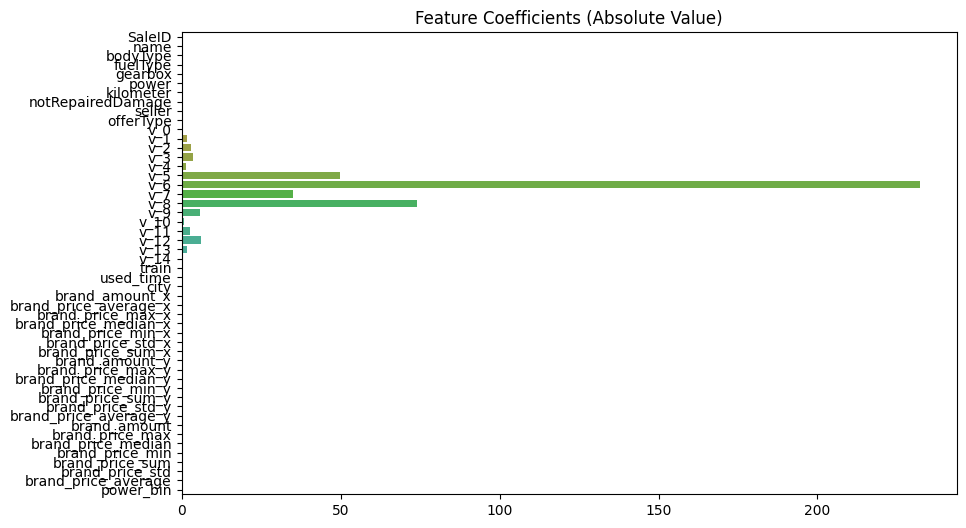

In [70]:
model = LinearRegression().fit(train_X, train_y_ln)
print('intercept:' + str(model.intercept_))

# 方案1：横向条形图（推荐）
plt.figure(figsize=(10, 6))
sns.barplot(x=abs(model.coef_), y=continuous_feature_names)
plt.title("Feature Coefficients (Absolute Value)")
plt.show()



intercept:9.09098942108167

特征系数：
SaleID: 0.000000 (绝对值: 0.000000)
name: 0.000000 (绝对值: 0.000000)
bodyType: 0.000000 (绝对值: 0.000000)
fuelType: 0.000000 (绝对值: 0.000000)
gearbox: 0.000000 (绝对值: 0.000000)
power: 0.007066 (绝对值: 0.007066)
kilometer: -0.000000 (绝对值: 0.000000)
notRepairedDamage: -0.000000 (绝对值: 0.000000)
seller: 0.000000 (绝对值: 0.000000)
offerType: 0.000000 (绝对值: 0.000000)
v_0: 0.000000 (绝对值: 0.000000)
v_1: 0.000000 (绝对值: 0.000000)
v_2: 0.000000 (绝对值: 0.000000)
v_3: -0.000000 (绝对值: 0.000000)
v_4: -0.000000 (绝对值: 0.000000)
v_5: 0.000000 (绝对值: 0.000000)
v_6: 0.000000 (绝对值: 0.000000)
v_7: -0.000000 (绝对值: 0.000000)
v_8: 0.000000 (绝对值: 0.000000)
v_9: -0.000000 (绝对值: 0.000000)
v_10: -0.000000 (绝对值: 0.000000)
v_11: -0.000000 (绝对值: 0.000000)
v_12: 0.000000 (绝对值: 0.000000)
v_13: -0.000000 (绝对值: 0.000000)
v_14: -0.000000 (绝对值: 0.000000)
train: 0.000000 (绝对值: 0.000000)
used_time: -0.000375 (绝对值: 0.000375)
city: 0.000000 (绝对值: 0.000000)
brand_amount_x: 0.000000 (绝对值: 0.000000)
brand_price

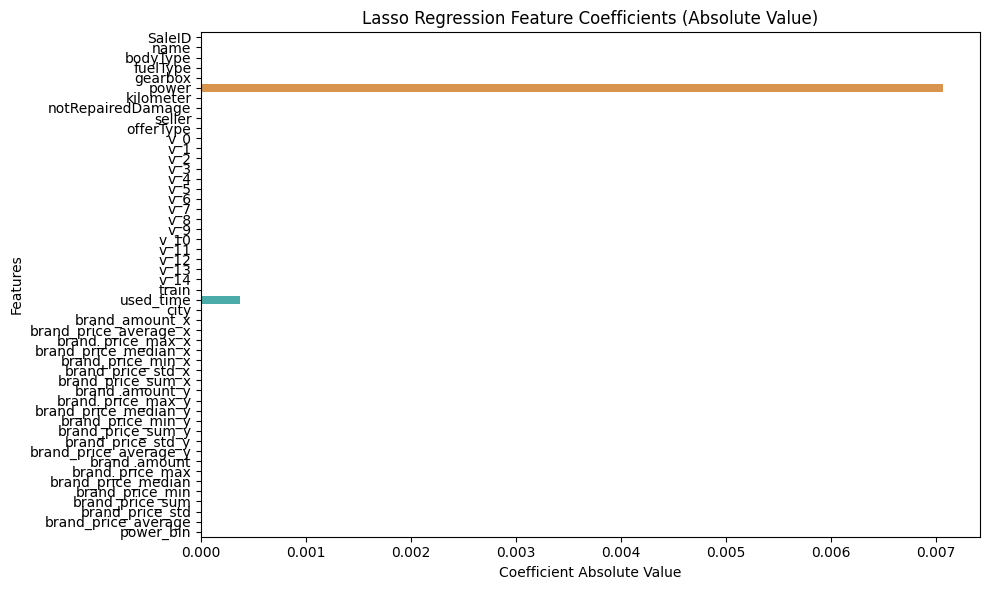

In [68]:
model = Lasso().fit(train_X, train_y_ln)
print('intercept:' + str(model.intercept_))

# 打印系数和特征名用于调试
print("\n特征系数：")
for feature, coef in zip(continuous_feature_names, model.coef_):
    print(f"{feature}: {coef:.6f} (绝对值: {abs(coef):.6f})")

# 创建系数绝对值的条形图
plt.figure(figsize=(10, 6))
sns.barplot(
    x=abs(model.coef_),  # 系数绝对值
    y=continuous_feature_names,  # 特征名称
    orient='h'  # 水平条形图
)
plt.title("Lasso Regression Feature Coefficients (Absolute Value)")
plt.xlabel("Coefficient Absolute Value")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [73]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost.sklearn import XGBRegressor
from lightgbm.sklearn import LGBMRegressor

In [74]:
models = [LinearRegression(),
          DecisionTreeRegressor(),
          RandomForestRegressor(),
          GradientBoostingRegressor(),
          MLPRegressor(solver='lbfgs', max_iter=100), 
          XGBRegressor(n_estimators = 100, objective='reg:squarederror'), 
          LGBMRegressor(n_estimators = 100)]

In [75]:
result = dict()
for model in models:
    model_name = str(model).split('(')[0]
    scores = cross_val_score(model, X=train_X, y=train_y_ln, verbose=0, cv = 5, scoring=make_scorer(mean_absolute_error))
    result[model_name] = scores
    print(model_name + ' is finished')

LinearRegression is finished
DecisionTreeRegressor is finished
RandomForestRegressor is finished
GradientBoostingRegressor is finished
MLPRegressor is finished
XGBRegressor is finished
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001195 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.166735
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001243 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4751
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.175322
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001139 seconds.
You can set `force_col_wise

In [76]:
result = pd.DataFrame(result)
result.index = ['cv' + str(x) for x in range(1, 6)]
result

,LinearRegression,DecisionTreeRegressor,RandomForestRegressor,GradientBoostingRegressor,MLPRegressor,XGBRegressor,LGBMRegressor
cv1,0.181918,0.191795,0.128403,0.153981,200.574912,0.134528,0.132653
cv2,0.186872,0.185523,0.129066,0.155279,1.041934,0.132016,0.132252
cv3,0.189409,0.181686,0.131024,0.159491,79.157660,0.135009,0.135683
cv4,0.184908,0.187451,0.125923,0.155594,82.106109,0.133719,0.132317
cv5,0.193990,0.187971,0.132912,0.159167,74.711877,0.140691,0.135726


In [77]:
objective = ['regression', 'regression_l1', 'mape', 'huber', 'fair']
num_leaves = [3,5,10,15,20,40, 55]
max_depth = [3,5,10,15,20,40, 55]
bagging_fraction = []
feature_fraction = []
drop_rate = []

In [78]:
best_obj = dict()
for obj in objective:
    model = LGBMRegressor(objective=obj)
    score = np.mean(cross_val_score(model, X=train_X, y=train_y_ln, verbose=0, cv=5, scoring=make_scorer(mean_absolute_error)))
    best_obj[obj] = score

best_leaves = dict()
for leaves in num_leaves:
    model = LGBMRegressor(objective=min(best_obj.items(), key=lambda x:x[1])[0], num_leaves=leaves)
    score = np.mean(cross_val_score(model, X=train_X, y=train_y_ln, verbose=0, cv=5, scoring=make_scorer(mean_absolute_error)))
    best_leaves[leaves] = score

best_depth = dict()
for depth in max_depth:
    model = LGBMRegressor(
        objective=min(best_obj.items(), key=lambda x:x[1])[0],
        num_leaves=min(best_leaves.items(), key=lambda x:x[1])[0],
        max_depth=depth
    )
    score = np.mean(cross_val_score(model, X=train_X, y=train_y_ln, verbose=0, cv=5, scoring=make_scorer(mean_absolute_error)))
    best_depth[depth] = score

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001195 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.166735
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001057 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4751
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.175322
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001158 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4756
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start tra

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001080 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.243019
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001052 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4751
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.256088
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001088 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4756
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start tra

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001208 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.243019
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001048 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.243019
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001172 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4751
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start tra

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001061 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4764
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.256088
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001068 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4764
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.256088
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000980 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.243019
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001058 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start tra

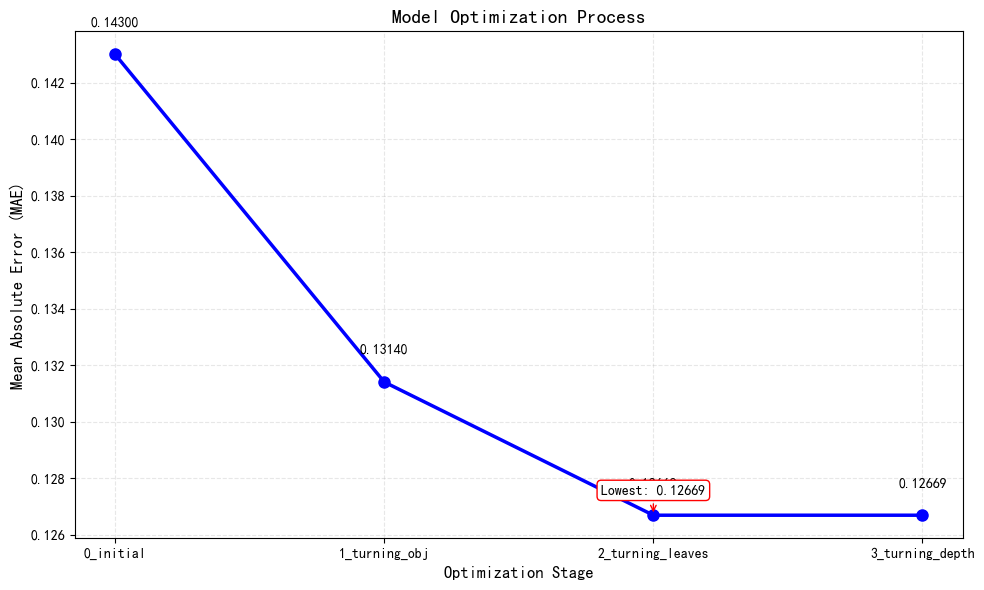

In [93]:
# 安全提取值（同上）
initial_mae = 0.143
obj_mae = safe_extract(best_obj)
leaves_mae = safe_extract(best_leaves)
depth_mae = safe_extract(best_depth)

# 创建数据
stages = ['0_initial', '1_turning_obj', '2_turning_leaves', '3_turning_depth']
mae_values = [initial_mae, obj_mae, leaves_mae, depth_mae]

# 创建折线图
plt.figure(figsize=(10, 6))
plt.plot(stages, mae_values, 
         marker='o', 
         markersize=8,
         linewidth=2.5,
         color='blue')

# 添加图表元素
plt.title("Model Optimization Process", fontsize=14)
plt.ylabel("Mean Absolute Error (MAE)", fontsize=12)
plt.xlabel("Optimization Stage", fontsize=12)

# 添加数据点标签
for i, val in enumerate(mae_values):
    plt.text(i, val + 0.001, f"{val:.5f}", ha='center', fontsize=10)

# 标记最低点
min_index = np.argmin(mae_values)
min_val = mae_values[min_index]
plt.annotate(f'Lowest: {min_val:.5f}', 
            (min_index, min_val), 
            xytext=(0, 15), 
            textcoords='offset points',
            ha='center',
            fontsize=10,
            arrowprops=dict(arrowstyle='->', color='red'),
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='red'))

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('model_optimization_matplotlib.png', dpi=300, bbox_inches='tight')
plt.show()

In [94]:
from sklearn.model_selection import GridSearchCV

In [96]:
parameters = {'objective': objective , 'num_leaves': num_leaves, 'max_depth': max_depth}
model = LGBMRegressor()
clf = GridSearchCV(model, parameters, cv=5)
clf = clf.fit(train_X, train_y)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001126 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 6058.036890
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001080 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4751
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 6109.694600
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000998 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4756
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Sta

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001222 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4764
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 6134.958769
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training becau

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001099 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4756
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 6100.372607
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000948 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4764
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 6134.958769
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001054 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Sta

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped t

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001054 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 6058.036890
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001103 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4764
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 6134.958769
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

... (174 outputs left out)

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped t

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001060 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 6058.036890
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001014 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4751
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 6109.694600
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001077 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4756
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Sta

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001066 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4751
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 6109.694600
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001456 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4772
[LightGBM] [Info] Number of data points in the train set: 19585, number of used features: 26
[LightGBM] [Info] Start training from score 6105.896502


In [97]:
model = LGBMRegressor(objective='regression',
                      num_leaves=55,
                      max_depth=15)

In [98]:
np.mean(cross_val_score(model, X=train_X, y=train_y_ln, verbose=0, cv = 5, scoring=make_scorer(mean_absolute_error)))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001100 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4754
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.166735
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001056 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4751
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start training from score 8.175322
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001046 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4756
[LightGBM] [Info] Number of data points in the train set: 15668, number of used features: 26
[LightGBM] [Info] Start tra

0.129068222492966